# Data split and augmentation

Run this notebook before the two ResNet18 notebooks. Start with `cleaned dataset`.
Use stratified `train_test_split` twice: reserve 15% for test, then reserve 15% of the remaining 85% for validation.
The final proportions are approximately **72.25% train / 12.75% validation / 15% test**, subject to integer rounding.

Create four augmented views per training image only. Validation and test use original images.
Copies go into `split_dataset`; augmented training views go into `augmented_train`. Original files remain unchanged.
All views of a source image stay in the training partition. Matching for leakage checks uses only file-byte SHA-256.

Dependencies: `pip install scikit-learn pandas numpy pillow matplotlib nbformat`.
Reference: [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html).

In [1]:
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import train_test_split
import hashlib
import json
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance
from IPython.display import display

ROOT = Path.cwd().resolve()
SOURCE = ROOT / 'cleaned dataset'
SPLIT_DIR = ROOT / 'split_dataset'
AUG_DIR = ROOT / 'augmented_train'
SEED = 42
TEST_FRACTION = 0.15
VALIDATION_FRACTION = 0.15  # Fraction of the initial 85% training portion.
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
assert SOURCE.is_dir(), 'Open this notebook from the project folder.'

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

paths = sorted(p for p in SOURCE.rglob('*') if p.is_file() and p.suffix.lower() in EXTENSIONS)
assert paths
with ThreadPoolExecutor(max_workers=4) as pool:
    hashes = list(pool.map(sha256_file, paths))
data = pd.DataFrame({'path': [p.relative_to(SOURCE).as_posix() for p in paths],
                     'class': [p.relative_to(SOURCE).parts[0] for p in paths],
                     'sha256': hashes})
assert data.sha256.is_unique, 'Exact duplicate files must be resolved before splitting.'
assert data['class'].value_counts().min() >= 10
print(f'{len(data)} images across {data["class"].nunique()} classes')

3893 images across 9 classes


## Split into train, validation and test

In [2]:
train_pool, test = train_test_split(
    data, test_size=TEST_FRACTION, random_state=SEED, stratify=data['class'])
train, validation = train_test_split(
    train_pool, test_size=VALIDATION_FRACTION, random_state=SEED, stratify=train_pool['class'])
parts = {'train': train, 'validation': validation, 'test': test}
manifest = pd.concat([frame.assign(split=name) for name, frame in parts.items()], ignore_index=True)
manifest = manifest.sort_values(['split', 'path']).reset_index(drop=True)
assert len(manifest) == len(data) and manifest.path.is_unique
for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert set(parts[a].sha256).isdisjoint(parts[b].sha256)

SPLIT_DIR.mkdir(exist_ok=True)
manifest_path = SPLIT_DIR / 'manifest.csv'
if manifest_path.exists():
    previous = pd.read_csv(manifest_path)
    pd.testing.assert_frame_equal(previous, manifest, check_dtype=False)
else:
    manifest.to_csv(manifest_path, index=False)

expected = {f'{r.split}/{r.path}' for r in manifest.itertuples(index=False)}
existing = {p.relative_to(SPLIT_DIR).as_posix() for p in SPLIT_DIR.rglob('*')
            if p.is_file() and p.suffix.lower() in EXTENSIONS}
assert not existing - expected, 'Unexpected split images; use a new output directory.'

def copy_image(row):
    target = SPLIT_DIR / row.split / row.path
    target.parent.mkdir(parents=True, exist_ok=True)
    if not target.exists():
        shutil.copy2(SOURCE / row.path, target)
    assert sha256_file(target) == row.sha256, f'Copy mismatch: {target}'

with ThreadPoolExecutor(max_workers=4) as pool:
    list(pool.map(copy_image, manifest.itertuples(index=False)))
counts = pd.crosstab(manifest['class'], manifest['split'])[['train', 'validation', 'test']]
display(counts)
print('Total:', counts.sum().to_dict())

split,train,validation,test
class,,,
Bacterial Leaf Blight,282,50,58
Brown Spot,288,51,60
Healthy Rice Leaf,301,53,63
Leaf Blast,391,69,81
Leaf scald,293,52,61
Narrow Brown Leaf Spot,297,52,61
Rice Hispa,274,49,57
Rice Turgro,289,51,60
Sheath Blight,397,70,83


Total: {'train': 2812, 'validation': 497, 'test': 584}


## Plot class distribution

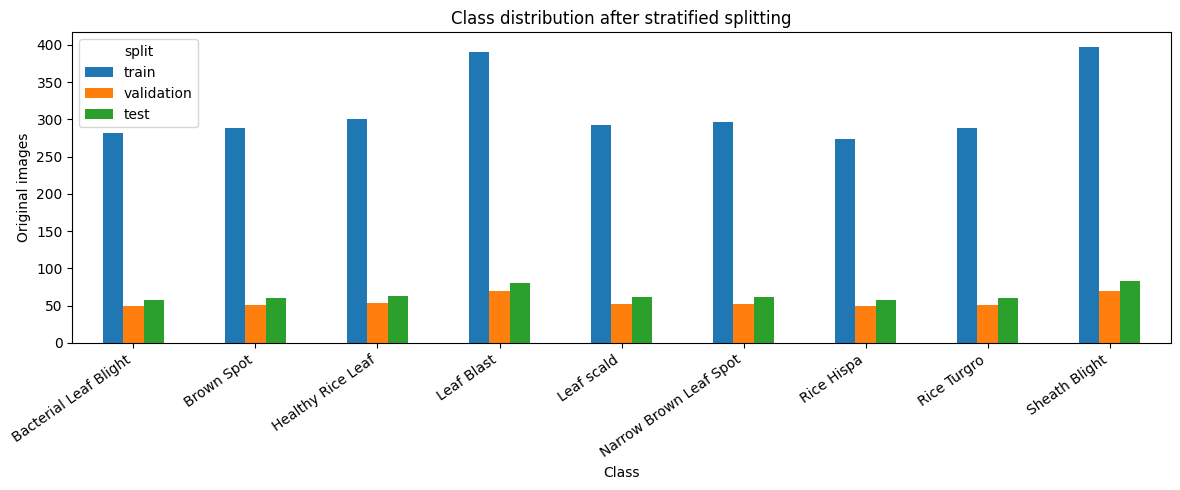

In [3]:
ax = counts.plot.bar(figsize=(12, 5), rot=35)
ax.set(title='Class distribution after stratified splitting', xlabel='Class', ylabel='Original images')
plt.xticks(ha='right')
plt.tight_layout()
plt.show()

## Create four training views

Each training image produces exactly four views: horizontal flip, a −15° rotation,
a +15° rotation, and a brightness/contrast adjustment. Views are 256 × 256 RGB PNGs.
Rotation uses reflected padding before the center crop. These four views replace the training input;
the unmodified training originals remain in `split_dataset/train`.
The model notebooks use the same saved views for a fair comparison.

In [4]:
VIEW_SIZE = 256
AUGMENTATION_VERSION = 'four_views_v1'

def make_views(path):
    with Image.open(path) as opened:
        image = ImageOps.exif_transpose(opened).convert('RGB')
        image = ImageOps.fit(image, (VIEW_SIZE, VIEW_SIZE), method=Image.Resampling.LANCZOS)
    pad = 64
    padded = Image.fromarray(np.pad(np.asarray(image), ((pad, pad), (pad, pad), (0, 0)), mode='reflect'))
    def rotate(angle):
        return padded.rotate(angle, resample=Image.Resampling.BICUBIC).crop(
            (pad, pad, pad + VIEW_SIZE, pad + VIEW_SIZE))
    return [ImageOps.mirror(image), rotate(-15), rotate(15),
            ImageEnhance.Contrast(ImageEnhance.Brightness(image).enhance(1.15)).enhance(1.10)]

augmentation_rows = []
for row in train.sort_values('path').itertuples(index=False):
    for view in range(1, 5):
        augmentation_rows.append({'source_path': row.path, 'class': Path(row.path).parts[0],
                                  'source_sha256': row.sha256, 'view': view,
                                  'path': f'{row.path}.view{view}.png'})
aug_manifest = pd.DataFrame(augmentation_rows)
AUG_DIR.mkdir(exist_ok=True)
config = {'version': AUGMENTATION_VERSION, 'view_size': VIEW_SIZE, 'views_per_image': 4}
config_path = AUG_DIR / 'config.json'
if config_path.exists():
    assert json.loads(config_path.read_text()) == config, 'Augmentation settings changed; use a new folder.'
else:
    config_path.write_text(json.dumps(config, indent=2), encoding='utf-8')
aug_manifest_path = AUG_DIR / 'manifest.csv'
if aug_manifest_path.exists():
    pd.testing.assert_frame_equal(pd.read_csv(aug_manifest_path), aug_manifest, check_dtype=False)
else:
    aug_manifest.to_csv(aug_manifest_path, index=False)
expected_views = set(aug_manifest.path)
existing_views = {p.relative_to(AUG_DIR).as_posix() for p in AUG_DIR.rglob('*.png')}
assert not existing_views - expected_views

def save_views(relative):
    views = make_views(SOURCE / relative)
    for number, view in enumerate(views, 1):
        target = AUG_DIR / f'{relative}.view{number}.png'
        target.parent.mkdir(parents=True, exist_ok=True)
        view.save(target, format='PNG')

with ThreadPoolExecutor(max_workers=4) as pool:
    list(pool.map(save_views, train.sort_values('path')['path']))
assert {p.relative_to(AUG_DIR).as_posix() for p in AUG_DIR.rglob('*.png')} == expected_views
assert len(aug_manifest) == 4 * len(train)
assert set(aug_manifest.source_path) == set(train.path)
assert aug_manifest.groupby('source_path').size().eq(4).all()
print(f'Saved {len(aug_manifest)} training views from {len(train)} originals.')

Saved 11248 training views from 2812 originals.


## Preview the four views

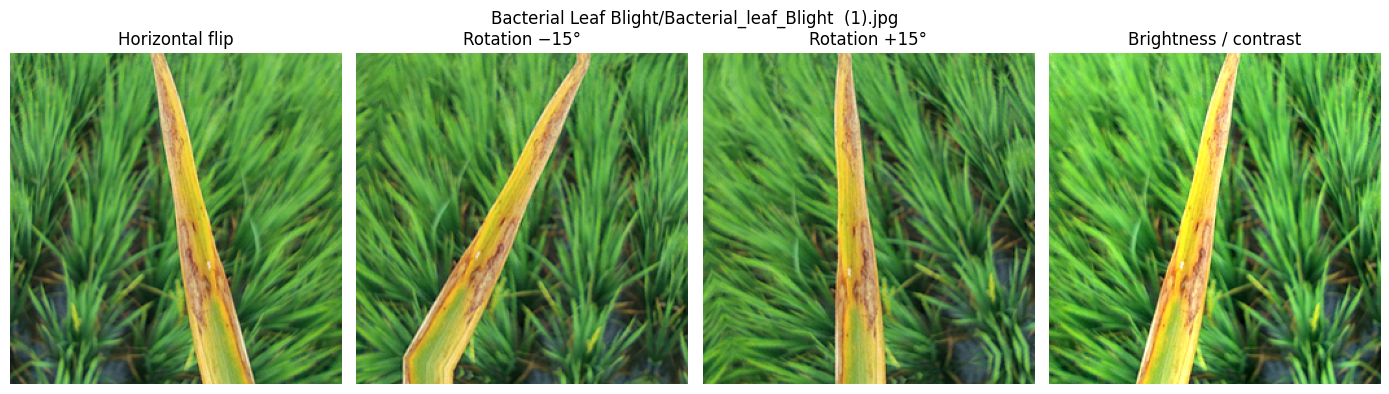

In [5]:
sample_path = train.sort_values('path').iloc[0]['path']
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, view, title in zip(axes, make_views(SOURCE / sample_path),
                          ['Horizontal flip', 'Rotation −15°', 'Rotation +15°', 'Brightness / contrast']):
    ax.imshow(view)
    ax.set_title(title)
    ax.axis('off')
fig.suptitle(sample_path)
plt.tight_layout()
plt.show()